Employee turnover prediction Using Machine Learning approaches and performance analysis of ML algorithms with ***Secondary dataset***.

In [ ]:
# python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, precision_recall_curve, average_precision_score
)
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.exceptions import NotFittedError
import pickle

sns.set_style('whitegrid')
plt.style.use('seaborn-v0_8-whitegrid')

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [ ]:
# To mount google drive with the this file
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# To read .csv file from an specific path
df = pd.read_csv('/content/drive/MyDrive/dis/employee_10000.csv',index_col=0)
df = df.reset_index()
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Employee_ID                    10000 non-null  int64 
 1   Age                            10000 non-null  int64 
 2   Gender                         10000 non-null  object
 3   Marital_Status                 10000 non-null  object
 4   Department                     10000 non-null  object
 5   Job_Role                       10000 non-null  object
 6   Job_Level                      10000 non-null  int64 
 7   Monthly_Income                 10000 non-null  int64 
 8   Hourly_Rate                    10000 non-null  int64 
 9   Years_at_Company               10000 non-null  int64 
 10  Years_in_Current_Role          10000 non-null  int64 
 11  Years_Since_Last_Promotion     10000 non-null  int64 
 12  Work_Life_Balance              10000 non-null  int64 
 13  Jo

In [ ]:

duplicates = df[df.duplicated()]    # To check dupicate values
print(duplicates)
df.rename(columns={"Attrition": "Turnover"}, inplace=True)  # renameing 'Attrition' feature with 'Turnover'

df.head()   # To print dataset top 5 colmun

Empty DataFrame
Columns: [Employee_ID, Age, Gender, Marital_Status, Department, Job_Role, Job_Level, Monthly_Income, Hourly_Rate, Years_at_Company, Years_in_Current_Role, Years_Since_Last_Promotion, Work_Life_Balance, Job_Satisfaction, Performance_Rating, Training_Hours_Last_Year, Overtime, Project_Count, Average_Hours_Worked_Per_Week, Absenteeism, Work_Environment_Satisfaction, Relationship_with_Manager, Job_Involvement, Distance_From_Home, Number_of_Companies_Worked, Attrition]
Index: []

[0 rows x 26 columns]


,Employee_ID,Age,Gender,Marital_Status,Department,Job_Role,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,...,Overtime,Project_Count,Average_Hours_Worked_Per_Week,Absenteeism,Work_Environment_Satisfaction,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Turnover
0,1,58,Male,Single,Finance,Manager,5,7332,81,24,...,No,9,48,16,4,1,1,49,3,No
1,2,48,Female,Divorced,HR,Assistant,4,6069,55,18,...,Yes,9,57,10,4,1,1,25,1,No
2,3,34,Female,Married,Marketing,Manager,4,11485,65,6,...,Yes,3,55,1,1,4,3,21,1,Yes
3,4,27,Female,Divorced,HR,Manager,4,18707,28,12,...,No,9,53,2,3,4,1,46,2,No
4,5,40,Male,Married,HR,Analyst,1,16398,92,3,...,No,1,54,11,1,1,1,43,4,No


**Exploratory Data Analysis (EDA)**

In [ ]:
df_eda = df.copy()      # copying main dataset
df_eda['Turnover_numeric'] = df_eda['Turnover'].apply(lambda x: 1 if x == 'Yes' else 0)     # creating 'Turnover_numeric' column to hold numearical value (0/1) for Turnover feature.

print("Dataset Info for EDA:")
df_eda.info()           # to print dataset info
print("\nUnique values in turnover:", df_eda['Turnover'].unique())
print("\nValue counts for turnover:\n", df_eda['Turnover'].value_counts())


Dataset Info for EDA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Employee_ID                    10000 non-null  int64 
 1   Age                            10000 non-null  int64 
 2   Gender                         10000 non-null  object
 3   Marital_Status                 10000 non-null  object
 4   Department                     10000 non-null  object
 5   Job_Role                       10000 non-null  object
 6   Job_Level                      10000 non-null  int64 
 7   Monthly_Income                 10000 non-null  int64 
 8   Hourly_Rate                    10000 non-null  int64 
 9   Years_at_Company               10000 non-null  int64 
 10  Years_in_Current_Role          10000 non-null  int64 
 11  Years_Since_Last_Promotion     10000 non-null  int64 
 12  Work_Life_Balance              10000 no

In [ ]:
df_eda.head()       # to print first 5 rows of copied dataset

,Employee_ID,Age,Gender,Marital_Status,Department,Job_Role,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,...,Project_Count,Average_Hours_Worked_Per_Week,Absenteeism,Work_Environment_Satisfaction,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Turnover,Turnover_numeric
0,1,58,Male,Single,Finance,Manager,5,7332,81,24,...,9,48,16,4,1,1,49,3,No,0
1,2,48,Female,Divorced,HR,Assistant,4,6069,55,18,...,9,57,10,4,1,1,25,1,No,0
2,3,34,Female,Married,Marketing,Manager,4,11485,65,6,...,3,55,1,1,4,3,21,1,Yes,1
3,4,27,Female,Divorced,HR,Manager,4,18707,28,12,...,9,53,2,3,4,1,46,2,No,0
4,5,40,Male,Married,HR,Analyst,1,16398,92,3,...,1,54,11,1,1,1,43,4,No,0


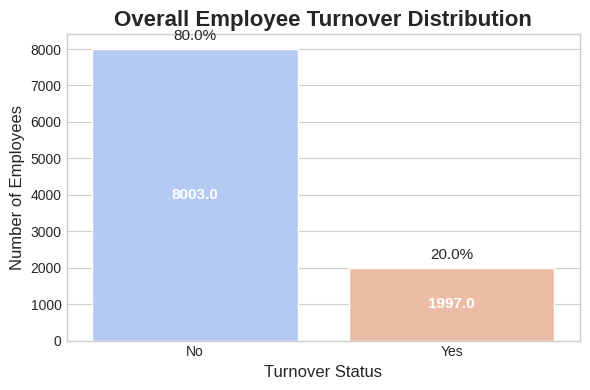

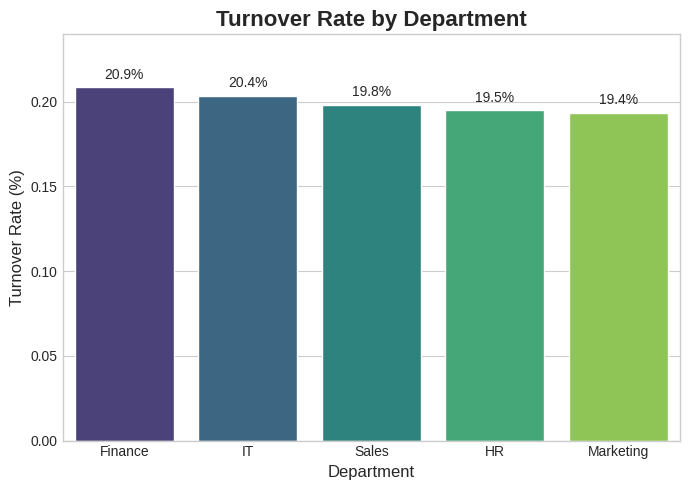

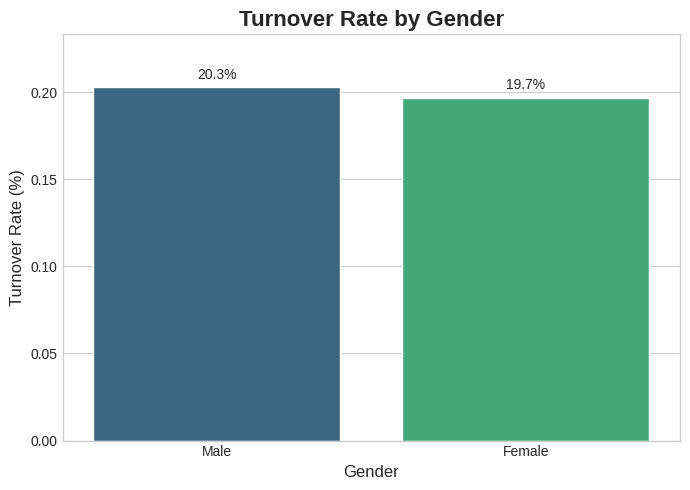

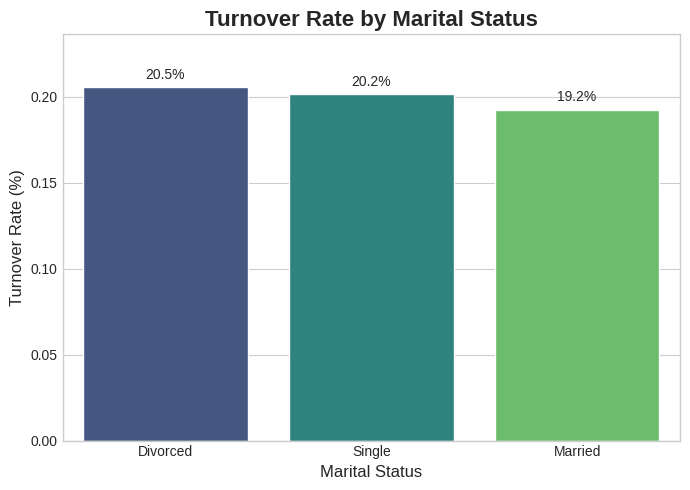

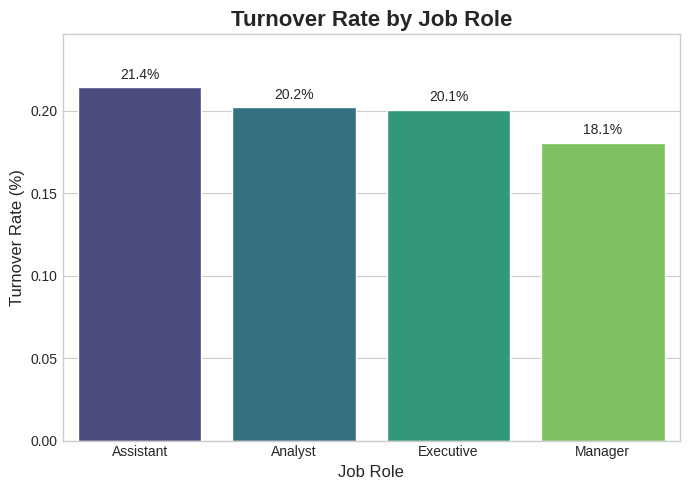

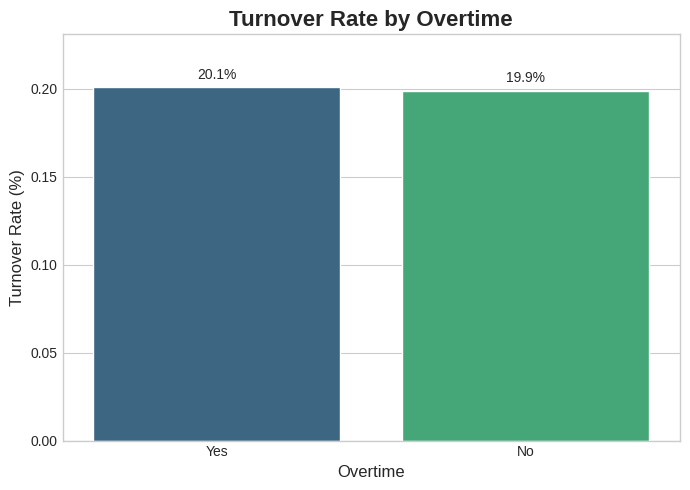

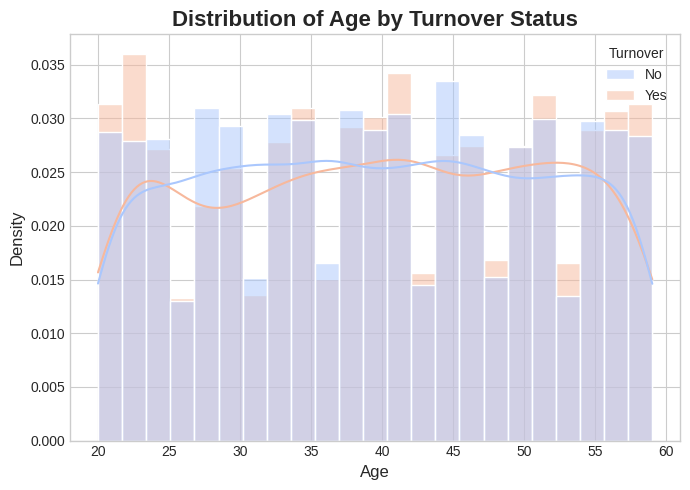

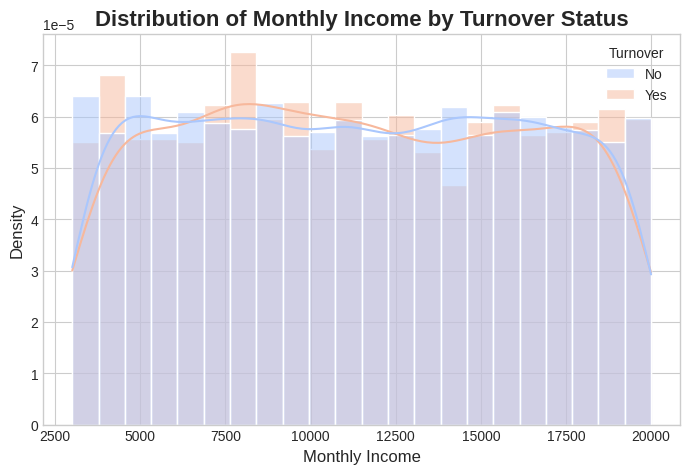

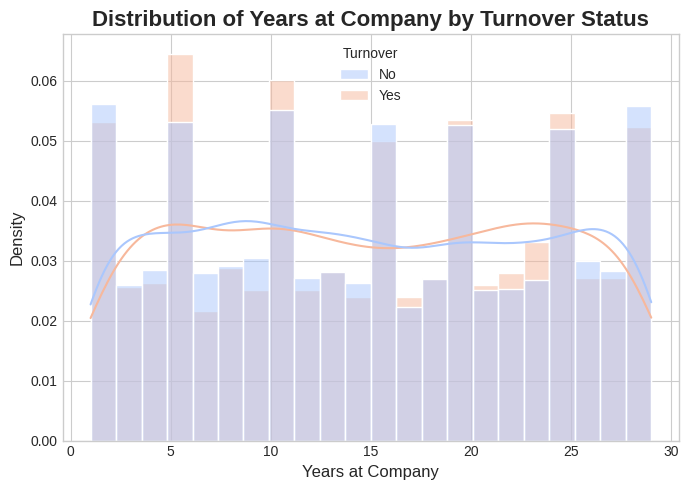

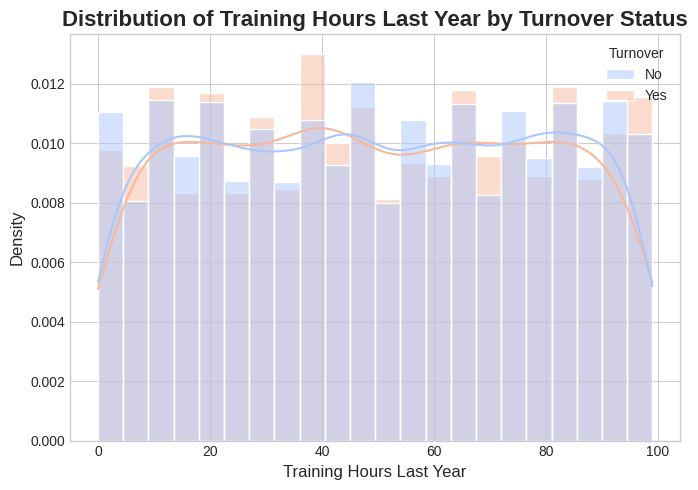

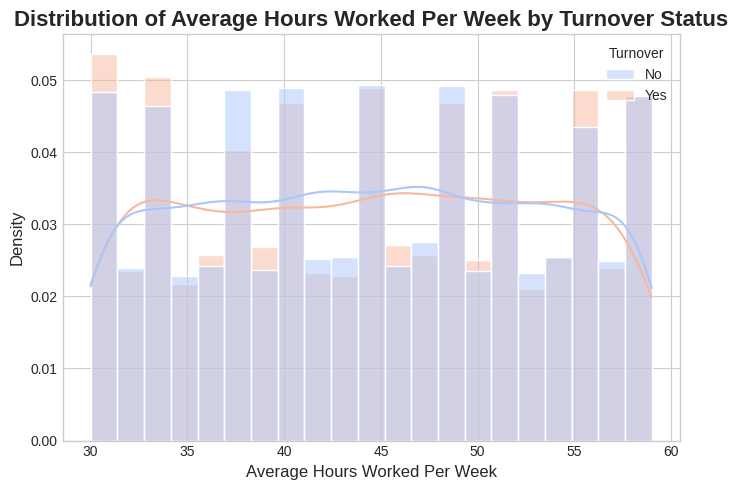

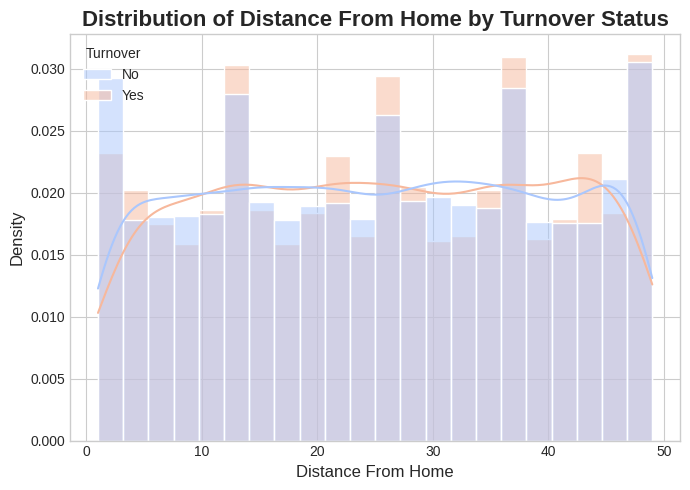

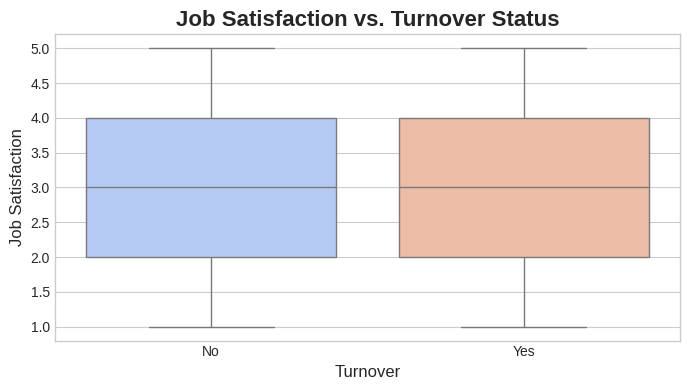

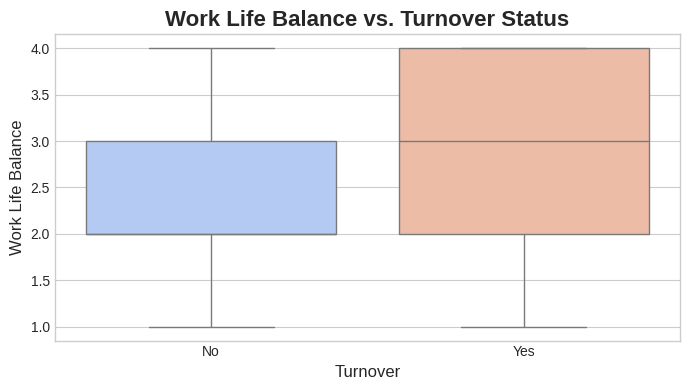

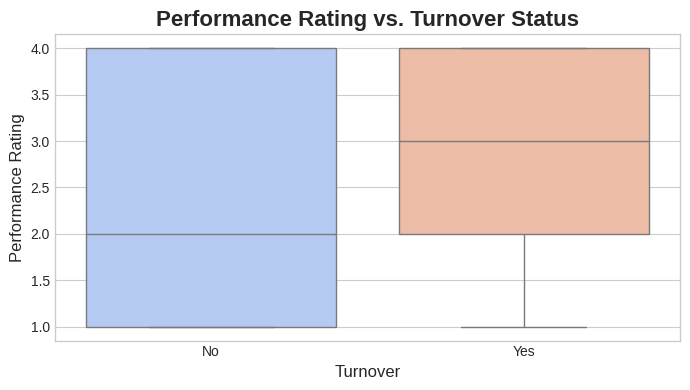

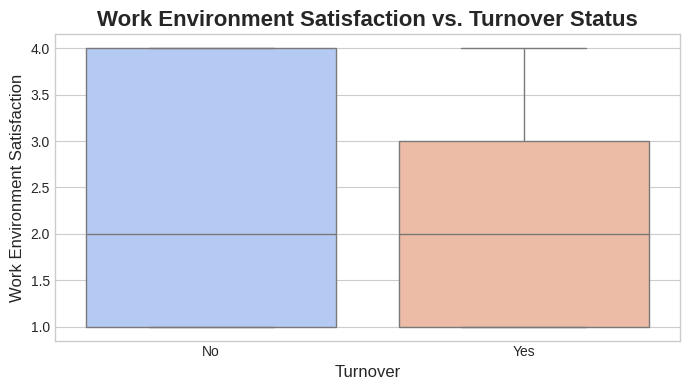

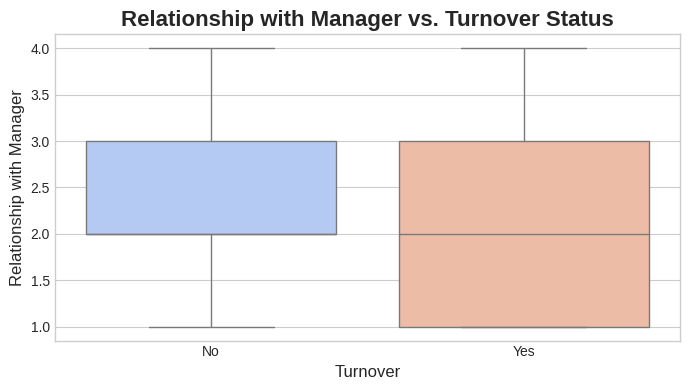

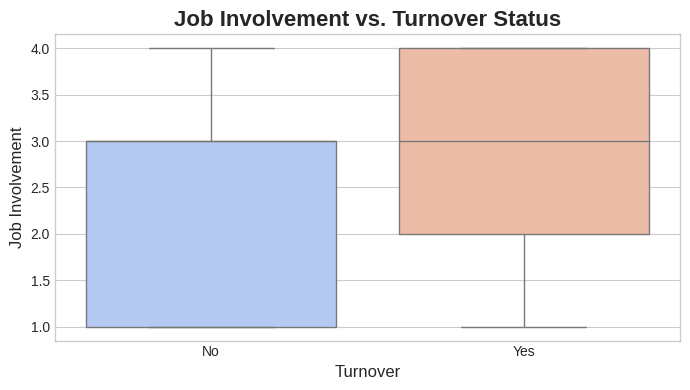

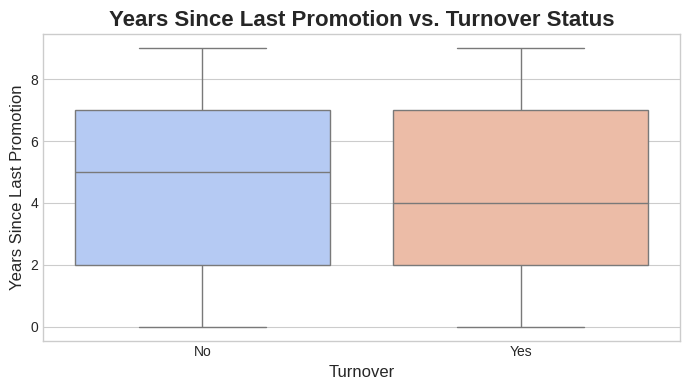

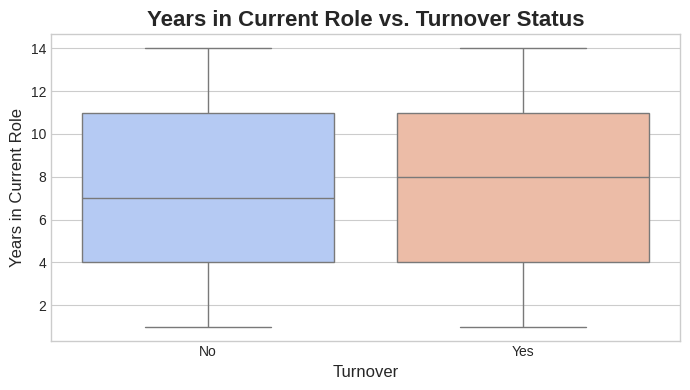

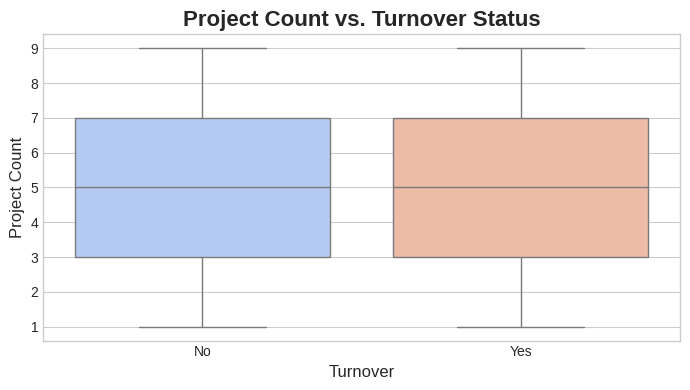

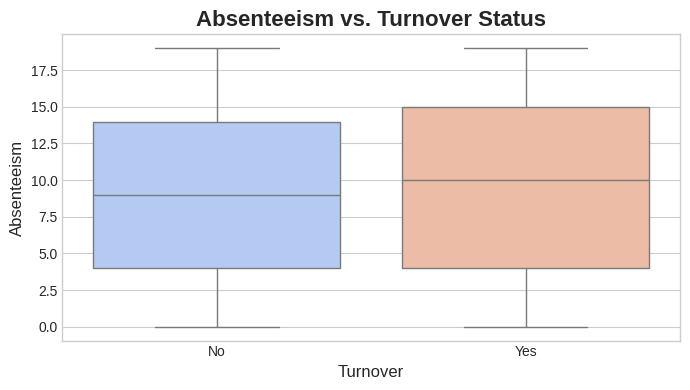

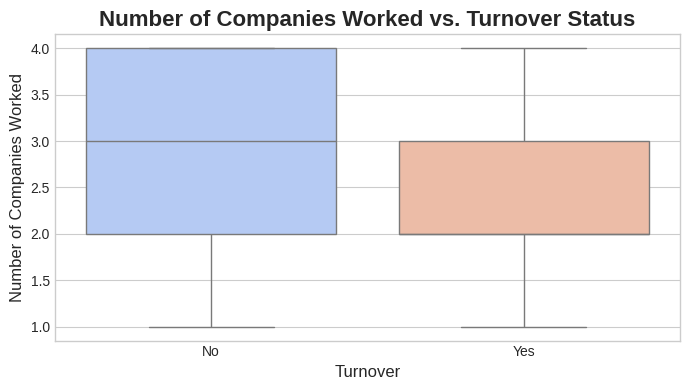

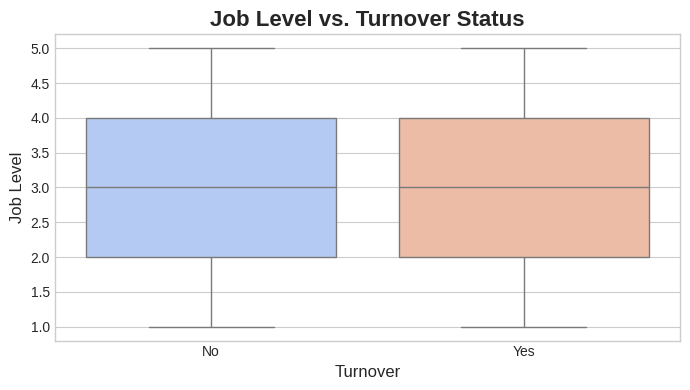

In [ ]:
# Exploratory Data Analysis (EDA)

# function to calculate employee turnover rate for categorical features
def plot_turnover_rate(df, column, title, rotation=0, figsize=(6, 4), order=None):
    plt.figure(figsize=figsize)
    turnover_rates = df.groupby(column)['Turnover_numeric'].mean().sort_values(ascending=False)
    if order:
        turnover_rates = turnover_rates.reindex(order)
    ax = sns.barplot(x=turnover_rates.index, y=turnover_rates.values, palette='viridis', order=order)
    plt.title(f'Turnover Rate by {title}', fontsize=16, fontweight='bold')
    plt.xlabel(title, fontsize=12)
    plt.ylabel('Turnover Rate (%)', fontsize=12)
    plt.xticks(rotation=rotation, ha='right' if rotation > 0 else 'center')
    plt.ylim(0, max(turnover_rates.values) * 1.15)
    for p in ax.patches:
        ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 9),
                    textcoords='offset points', fontsize=10)
    plt.tight_layout()
    plt.show()

# function to calculate employee turnover rate for numerical features
def plot_distribution_numerical(df, column, title, figsize=(7, 5)):
    plt.figure(figsize=figsize)
    sns.histplot(data=df, x=column, hue='Turnover', kde=True, stat='density', common_norm=False, palette='coolwarm')
    plt.title(f'Distribution of {title} by Turnover Status', fontsize=16, fontweight='bold')
    plt.xlabel(title, fontsize=12)
    plt.ylabel('Density', fontsize=12)
    plt.tight_layout()
    plt.show()

# function to compare (boxplot) turnover status with numerical/ordinal features
def plot_boxplot_numerical(df, column, title, figsize=(7, 4)):
    plt.figure(figsize=figsize)
    sns.boxplot(data=df, x='Turnover', y=column, palette='coolwarm')
    plt.title(f'{title} vs. Turnover Status', fontsize=16, fontweight='bold')
    plt.xlabel('Turnover', fontsize=12)
    plt.ylabel(title, fontsize=12)
    plt.tight_layout()
    plt.show()


# Overall Turnover Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_eda, x='Turnover', palette='coolwarm', order=df_eda['Turnover'].value_counts().index)
plt.title('Overall Employee Turnover Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Turnover Status', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
total = len(df_eda)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontsize=11)
    ax.annotate(f'{p.get_height()}', (x, y/2), ha='center', va='center', fontsize=11, color='white', fontweight='bold')
plt.tight_layout()
plt.show()


# Turnover Rate by Categorical Features
categorical_features = ['Department', 'Gender', 'Marital_Status', 'Job_Role', 'Overtime']
for col in categorical_features:
    figsize = (7, 5) if col == 'Job_Role' else (7, 5)
    rotation = 0 if col == 'Job_Role' else 0
    plot_turnover_rate(df_eda, col, col.replace('_', ' '), rotation=rotation, figsize=figsize)


# Distribution of Numerical Features by Turnover
numerical_features_dist = ['Age', 'Monthly_Income', 'Years_at_Company', 'Training_Hours_Last_Year', 'Average_Hours_Worked_Per_Week', 'Distance_From_Home']
for col in numerical_features_dist:
    plot_distribution_numerical(df_eda, col, col.replace('_', ' '))


# Box Plots of Numerical/Ordinal Features by Turnover
numerical_features_box = ['Job_Satisfaction', 'Work_Life_Balance', 'Performance_Rating',
                          'Work_Environment_Satisfaction', 'Relationship_with_Manager',
                          'Job_Involvement', 'Years_Since_Last_Promotion', 'Years_in_Current_Role',
                          'Project_Count', 'Absenteeism', 'Number_of_Companies_Worked', 'Job_Level']
for col in numerical_features_box:
    plot_boxplot_numerical(df_eda, col, col.replace('_', ' '))



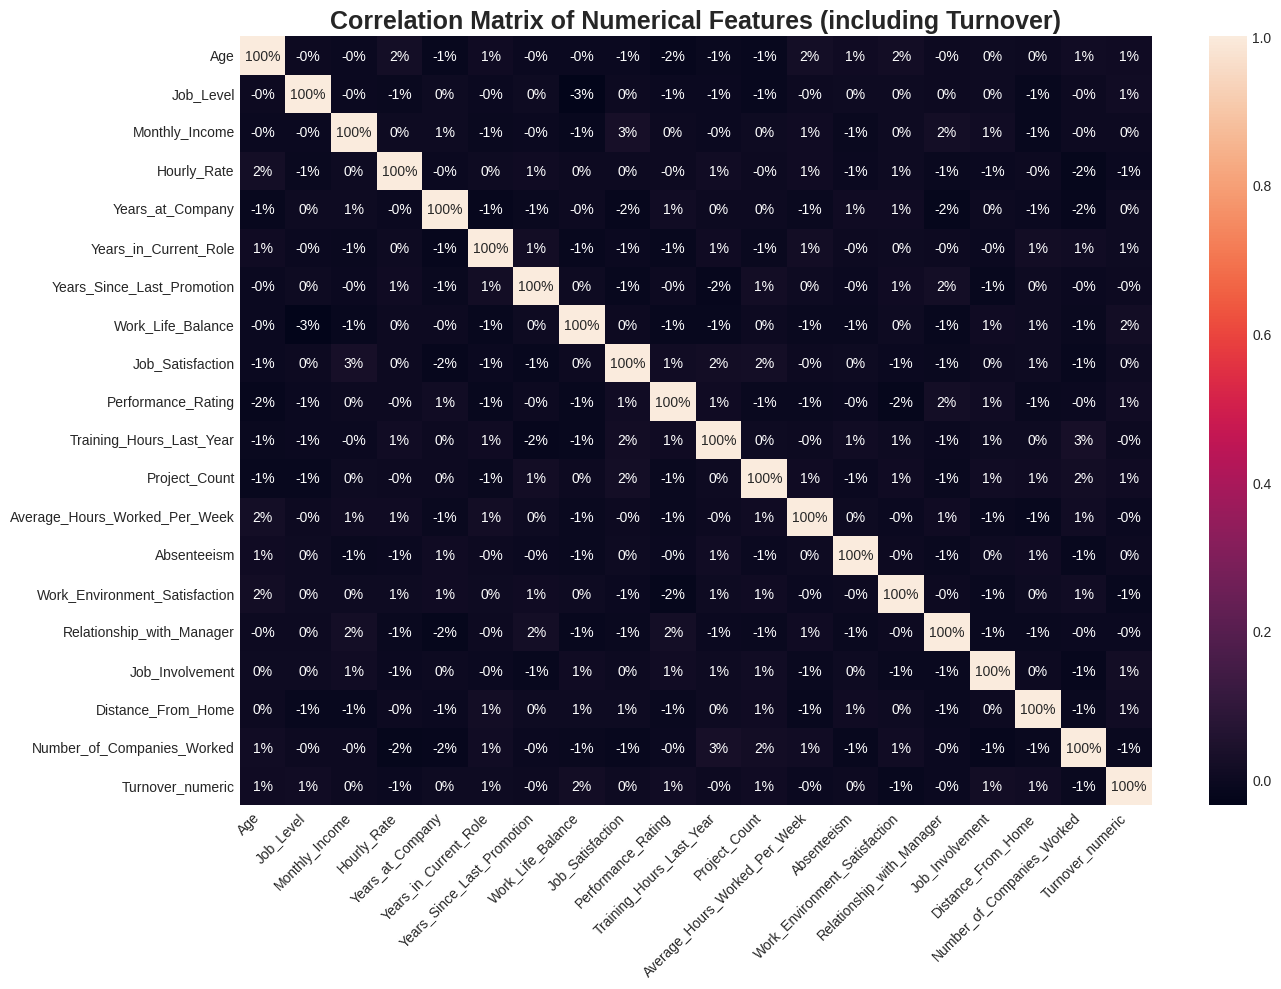

"\n#visualize the correlation\nnumerical_cols_for_corr = df_eda.select_dtypes(include=np.number).columns.tolist()\n\ncorr = df_eda[numerical_cols_for_corr].corr()\nplt.figure(figsize=(18, 14))  #14in by 14in\nsns.heatmap(corr, annot=True, fmt='.0%')\n"

In [ ]:
# Correlation Heatmap to sea co-relation between features and turnover
plt.figure(figsize=(14, 10))
numerical_cols_for_corr = df_eda.select_dtypes(include=np.number).columns.tolist()
if 'Employee_ID' in numerical_cols_for_corr:        # to drop Employee_ID column
    numerical_cols_for_corr.remove('Employee_ID')
correlation_matrix = df_eda[numerical_cols_for_corr].corr()
mask = np.triu(correlation_matrix)
sns.heatmap(correlation_matrix, annot=True, fmt='.0%')
plt.title('Correlation Matrix of Numerical Features (including Turnover)', fontsize=18, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



**Data preprocessing**

In [ ]:
# Data loading and preprocessing
# Define target column/variable and feature matrix

target = 'Turnover'             # defining target variable
features = df.drop(columns=[target, 'Employee_ID']).columns
X = df[features]
y = df[target].apply(lambda x: 1 if x == 'Yes' else 0)

# Separate categorical and numerical features
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

# Preprocessing pipelines
categorical_transformer = OneHotEncoder(handle_unknown='ignore', drop='first')
numerical_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Apply preprocessing to X
X_preprocessed = preprocessor.fit_transform(X)

# copying feature names to use when searching (for important predictors)---------
feature_names = preprocessor.get_feature_names_out()
# Turn the one‑hot / scaled matrix back into a DataFrame so we keep names (for most important predictors)------
X_pre_df = pd.DataFrame(X_preprocessed, columns=feature_names)

# Balancing the dataset with SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_preprocessed, y)

# Convert back to DataFrame so names persist (for most important predictors)------
X_resampled_df = pd.DataFrame(X_resampled, columns=feature_names)

In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.25, random_state=42, stratify=y_resampled)


**ML classifeirs/model training and analysis**

In [ ]:
# defining a function to train model and getting the performance matrices

results = {}        #   to save resualt value for each ML algorithm/model
print("--- Model Training and Evaluation start ---")
# for name, model_pipeline in models.items():
def train_model(name, model_pipeline):
    print(f"Training {name}...")
    model_pipeline.fit(X_train, y_train)
    print(f"Evaluating {name}...")
    y_train_pred = model_pipeline.predict(X_train)
    y_pred = model_pipeline.predict(X_test)
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]


    train_accuracy = accuracy_score(y_train, y_train_pred)      # getting training accuracy
    accuracy = accuracy_score(y_test, y_pred)                   # overall test accuracy
    precision = precision_score(y_test, y_pred)                 # positive prediction correcness
    recall = recall_score(y_test, y_pred)                       # positive case detection
    f1 = f1_score(y_test, y_pred)                               # precision-recall balance or overall classification quality
    roc_auc = roc_auc_score(y_test, y_prob)                     # class separation ability

    results[name] = {                                     # saving ML model's performance for later comparision
        "Train Accuracy": train_accuracy,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC AUC": roc_auc
    }

    print(f"\n{name} Performance:")
    print(f" Train Accuracy: {train_accuracy:.2f}")
    print(f" Test Accuracy: {accuracy:.2f}")
    print(f" Precision: {precision:.2f}")
    print(f" Recall: {recall:.2f}")
    print(f" F1-Score: {f1:.2f}")
    print(f" ROC AUC: {roc_auc:.2f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("-" * 30)

    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

--- Model Training and Evaluation start ---


In [ ]:
#Random Forest Classifier traing with best perameter
rf_pipeline = Pipeline(steps=[('classifier', RandomForestClassifier(random_state=42,
                                                                    n_estimators=1142,
                                                                    class_weight='balanced',
                                                                    bootstrap=False,
                                                                    max_depth=33,
                                                                    min_samples_leaf=3,
                                                                    min_samples_split=6))])

#Model training
name = "Random Forest"
model_pipeline = rf_pipeline

train_model(name, model_pipeline)


Training Random Forest...
Evaluating Random Forest...

Random Forest Performance:
 Train Accuracy: 1.00
 Test Accuracy: 0.87
 Precision: 1.00
 Recall: 0.74
 F1-Score: 0.85
 ROC AUC: 0.93

Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.88      2001
           1       1.00      0.74      0.85      2001

    accuracy                           0.87      4002
   macro avg       0.90      0.87      0.87      4002
weighted avg       0.90      0.87      0.87      4002

------------------------------
Confusion Matrix:
 [[2001    0]
 [ 524 1477]]


In [ ]:
#Decision Tree Classifier  traing with best perameters
dt_pipeline = Pipeline(steps=[('classifier', DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced',
    criterion='entropy',
    max_depth=22,
    min_samples_leaf=10,
    min_samples_split=17
    ))])

#Model training
name = "Decision Tree"
model_pipeline = dt_pipeline

train_model(name, model_pipeline)

Training Decision Tree...
Evaluating Decision Tree...

Decision Tree Performance:
 Train Accuracy: 0.90
 Test Accuracy: 0.79
 Precision: 0.81
 Recall: 0.76
 F1-Score: 0.78
 ROC AUC: 0.85

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80      2001
           1       0.81      0.76      0.78      2001

    accuracy                           0.79      4002
   macro avg       0.79      0.79      0.79      4002
weighted avg       0.79      0.79      0.79      4002

------------------------------
Confusion Matrix:
 [[1654  347]
 [ 490 1511]]


In [ ]:
# XGBoost Classifier traing with best perameters
xgb_pipeline = Pipeline(steps=[('classifier', XGBClassifier(
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    scale_pos_weight=sum(y_train==0)/sum(y_train==1),
    colsample_bytree=np.float64(0.8652745684046508),
    gamma=np.float64(3.4685880370166924),
    learning_rate=np.float64(0.05835192039808112),
    max_depth=9,
    n_estimators=777,
    reg_alpha=np.float64(0.8938925830509576),
    reg_lambda=np.float64(1.5771944224490615),
    subsample=np.float64(0.8762015600194113)
    ))])

#Model training
name = "XGBoost"
model_pipeline = xgb_pipeline

train_model(name, model_pipeline)


Training XGBoost...
Evaluating XGBoost...

XGBoost Performance:
 Train Accuracy: 0.88
 Test Accuracy: 0.87
 Precision: 1.00
 Recall: 0.73
 F1-Score: 0.85
 ROC AUC: 0.88

Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.88      2001
           1       1.00      0.73      0.85      2001

    accuracy                           0.87      4002
   macro avg       0.89      0.87      0.86      4002
weighted avg       0.89      0.87      0.86      4002

------------------------------
Confusion Matrix:
 [[2001    0]
 [ 533 1468]]


In [ ]:
# Support Vector Machine (SVM) Classifier traing with best perameters
svm_pipeline = Pipeline(steps=[('classifier', SVC(random_state=42,
                                                  gamma=1,
                                                  degree=2,
                                                  probability=True))])

#Model training
name = "Support Vector Machine"
model_pipeline = svm_pipeline

train_model(name, model_pipeline)


Training Support Vector Machine...
Evaluating Support Vector Machine...

Support Vector Machine Performance:
 Train Accuracy: 1.00
 Test Accuracy: 0.86
 Precision: 1.00
 Recall: 0.72
 F1-Score: 0.84
 ROC AUC: 0.99

Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      2001
           1       1.00      0.72      0.84      2001

    accuracy                           0.86      4002
   macro avg       0.89      0.86      0.86      4002
weighted avg       0.89      0.86      0.86      4002

------------------------------
Confusion Matrix:
 [[2001    0]
 [ 558 1443]]


In [ ]:
# Logistic regression classifier training with best perameters

lr_pipeline = Pipeline(steps=[('classifier', LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced',
    C=np.float64(4354.339080127637),
    solver='liblinear'
    ))])

#Model training
name = "Logistic regression"
model_pipeline = lr_pipeline

train_model(name, model_pipeline)


Training Logistic regression...
Evaluating Logistic regression...

Logistic regression Performance:
 Train Accuracy: 0.54
 Test Accuracy: 0.55
 Precision: 0.55
 Recall: 0.56
 F1-Score: 0.56
 ROC AUC: 0.56

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.54      0.55      2001
           1       0.55      0.56      0.56      2001

    accuracy                           0.55      4002
   macro avg       0.55      0.55      0.55      4002
weighted avg       0.55      0.55      0.55      4002

------------------------------
Confusion Matrix:
 [[1077  924]
 [ 872 1129]]


In [ ]:
# Gradient Boosting Classifier trainig with best perameters

gb_pipeline = Pipeline(steps=[('classifier', GradientBoostingClassifier(
    random_state=42,
    learning_rate=np.float64(0.022645093808785786),
    loss='exponential',
    max_depth=5,
    max_features='log2',
    min_samples_leaf=29,
    min_samples_split=47,
    n_estimators=717,
    subsample=np.float64(0.6850793501277221)
    ))])

#Model training
name = "Gradient Boosting"
model_pipeline = gb_pipeline

train_model(name, model_pipeline)


Training Gradient Boosting...
Evaluating Gradient Boosting...

Gradient Boosting Performance:
 Train Accuracy: 0.88
 Test Accuracy: 0.87
 Precision: 1.00
 Recall: 0.74
 F1-Score: 0.85
 ROC AUC: 0.89

Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.88      2001
           1       1.00      0.74      0.85      2001

    accuracy                           0.87      4002
   macro avg       0.90      0.87      0.87      4002
weighted avg       0.90      0.87      0.87      4002

------------------------------
Confusion Matrix:
 [[1998    3]
 [ 524 1477]]


In [ ]:
# CatBoost Classifier training with best perameters
!pip install catboost
from catboost import CatBoostClassifier

catb_pipeline = Pipeline(steps=[('classifier', CatBoostClassifier(verbose=0,
                                                                  random_state=42,
                                                                  class_weights=[1, 4],
                                                                  bagging_temperature=np.float64(0.9968742518459474),
                                                                  border_count=80,
                                                                  depth=10,
                                                                  iterations=1389,
                                                                  l2_leaf_reg=np.float64(7.7496442335926),
                                                                  learning_rate=np.float64(0.060377342342940586),
                                                                  random_strength=np.float64(8.980542894407137),
                                                                  rsm=np.float64(0.6820558561928028),
                                                                  subsample=np.float64(0.6762750882654667)
                                                                  ))])


name = "CatBoost"
model_pipeline = catb_pipeline

train_model(name, model_pipeline)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.6 MB/s eta 0:00:00
Training CatBoost...
Evaluating CatBoost...

CatBoost Performance:
 Train Accuracy: 1.00
 Test Accuracy: 0.88
 Precision: 0.97
 Recall: 0.79
 F1-Score: 0.87
 ROC AUC: 0.93

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      2001
           1       0.97      0.79      0.87      2001

    accuracy                           0.88      4002
   macro avg       0.89      0.88      0.88      4002
weighted avg       0.89      0.88      0.88      4002

------------------------------
Confusion Matrix:
 [[1946   55]
 [ 424 1577]]


In [ ]:
# Results summary of all trained classifiers

print("\n--- Overall Model Performance Summary ---")
results_df = pd.DataFrame(results).T
print(results_df.round(2))

best_f1_model = results_df['F1-Score'].idxmax()             # to print best model based on f1-score
best_roc_auc_model = results_df['ROC AUC'].idxmax()         # to print best model based on ROC AUC curve
print(f"\nBest Model based on F1-Score: {best_f1_model} ({results_df.loc[best_f1_model, 'F1-Score']:.2f})")
print(f"Best Model based on ROC AUC: {best_roc_auc_model} ({results_df.loc[best_roc_auc_model, 'ROC AUC']:.2f})")



--- Overall Model Performance Summary ---
                        Train Accuracy  Accuracy  Precision  Recall  F1-Score  \
Random Forest                     1.00      0.87       1.00    0.74      0.85   
Decision Tree                     0.90      0.79       0.81    0.76      0.78   
XGBoost                           0.88      0.87       1.00    0.73      0.85   
Support Vector Machine            1.00      0.86       1.00    0.72      0.84   
Logistic regression               0.54      0.55       0.55    0.56      0.56   
Gradient Boosting                 0.88      0.87       1.00    0.74      0.85   
CatBoost                          1.00      0.88       0.97    0.79      0.87   

                        ROC AUC  
Random Forest              0.93  
Decision Tree              0.85  
XGBoost                    0.88  
Support Vector Machine     0.99  
Logistic regression        0.56  
Gradient Boosting          0.89  
CatBoost                   0.93  

Best Model based on F1-Score: CatBo


--- Generating Predictions ---
Predicting with Random Forest...
Predicting with Decision Tree...
Predicting with XGBoost...
Predicting with Support Vector Machine...
Predicting with Logistic regression...
Predicting with Gradient Boosting...
Predicting with CatBoost...
Done generating predictions.

--- Plotting Metrics ---


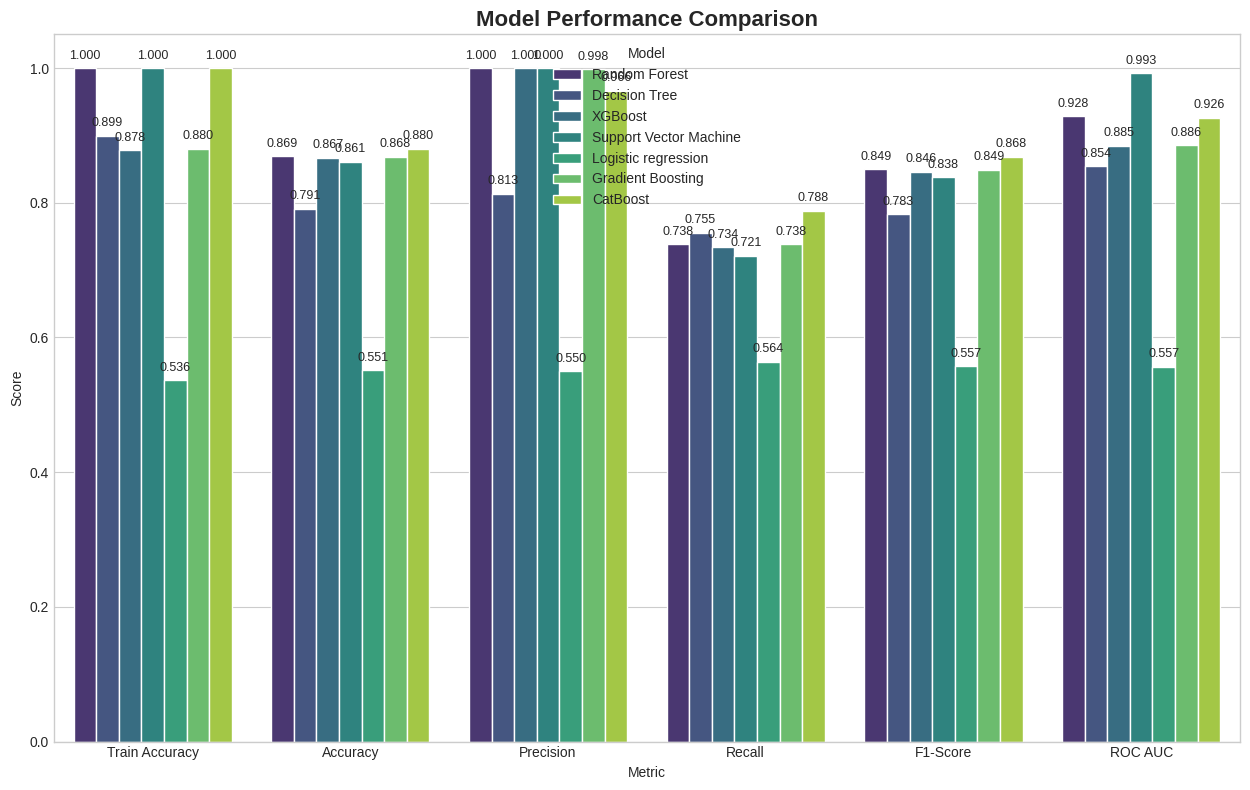


--- Confusion Matrices ---


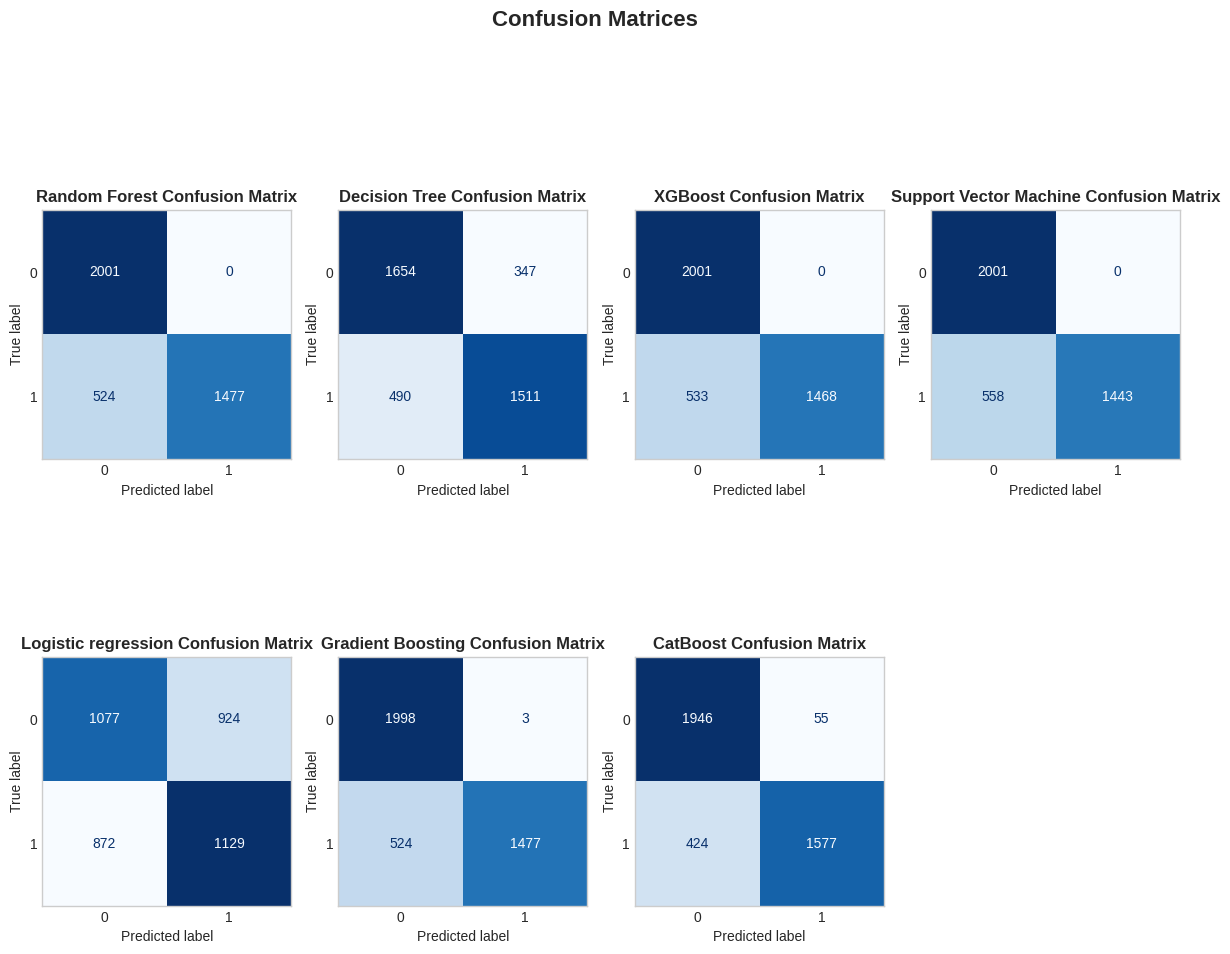


--- ROC Curves ---


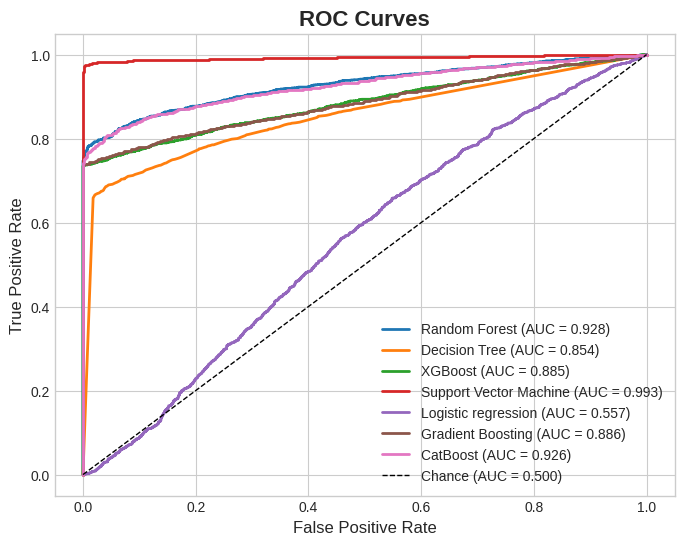


--- Precision-Recall Curves ---


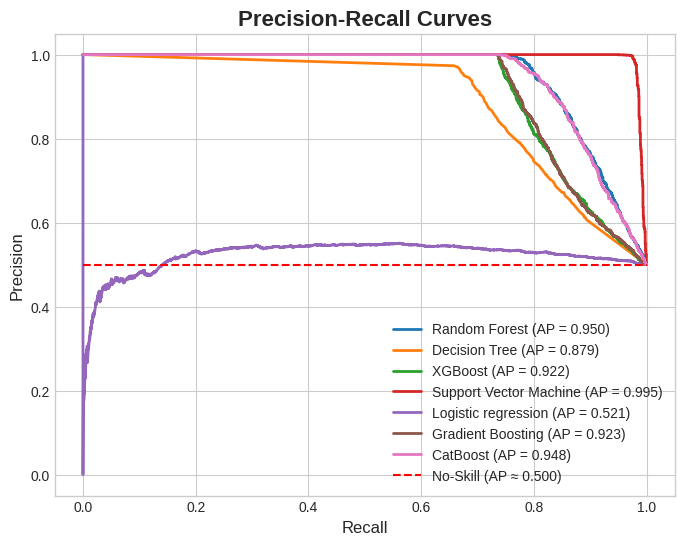


--- Visualization Done ---


In [ ]:
# to visualize classifier's confusion matrices, ROC curve, precision-recall curve and model comparison

predictions = {}
probabilities = {}
models = {
    "Random Forest": rf_pipeline,
    "Decision Tree": dt_pipeline,
    "XGBoost": xgb_pipeline,
    "Support Vector Machine": svm_pipeline,
    "Logistic regression": lr_pipeline,
    "Gradient Boosting": gb_pipeline,
    "CatBoost": catb_pipeline

}

# Generating predictions based on previousley trained classifiers
print("\n--- Generating Predictions ---")
for name, model_pipeline in models.items():
    print(f"Predicting with {name}...")
    try:
        if not hasattr(model_pipeline.steps[-1][1], 'classes_'):
            raise NotFittedError(f"Model '{name}' not fitted.")

        y_pred = model_pipeline.predict(X_test)
        y_prob = model_pipeline.predict_proba(X_test)[:, 1] if hasattr(model_pipeline, 'predict_proba') else None
        if y_prob is None:
            print(f"Warning: No predict_proba for {name}.")

        predictions[name] = y_pred
        if y_prob is not None:
            probabilities[name] = y_prob

    except NotFittedError as nfe:
        print(f"Skipping {name}: Not fitted. {nfe}")
    except AttributeError as ae:
        print(f"Attribute error with {name}: {ae}")
    except Exception as e:
        print(f"Error with {name}: {e}")

print("Done generating predictions.")

# Plotting Bar chart of performance matrices-----------
print("\n--- Plotting Metrics ---")
if 'results_df' in locals() and not results_df.empty:
    df_melted = results_df.reset_index().melt(id_vars='index', var_name='Metric', value_name='Score')
    df_melted.rename(columns={'index': 'Model'}, inplace=True)

    plt.figure(figsize=(14, 8))
    ax = sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', palette='viridis')
    plt.title('Model Performance Comparison', fontsize=16, fontweight='bold')
    plt.ylim(0, 1.05)

    for p in ax.patches:
        h = p.get_height()
        if h and h > 0.0001:
            ax.annotate(f'{h:.3f}', (p.get_x() + p.get_width()/2., h), ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontsize=9)

    plt.tight_layout(rect=[0, 0, 0.9, 1])
    plt.show()
else:
    print("Skipping bar chart: 'results_df' missing or empty.")

# --- Plotting Confusion Matrices ---
print("\n--- Confusion Matrices ---")
if predictions:
    fig, axes = plt.subplots(2, 4, figsize=(12, 10))
    axes = axes.flatten()
    plotted = 0

    for i, model_name in enumerate(models.keys()):
        if model_name not in predictions:
            if i < len(axes): axes[i].set_visible(False)
            continue
        if i >= len(axes): break

        cm = confusion_matrix(y_test, predictions[model_name])
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
        disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
        axes[i].set_title(f'{model_name} Confusion Matrix', fontsize=12, fontweight='bold')
        axes[i].grid(False)
        plotted += 1

    for j in range(plotted, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle('Confusion Matrices', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()
else:
    print("Skipping: No predictions.")

# --- Plotting ROC Curves ---
print("\n--- ROC Curves ---")
if probabilities and 'results_df' in locals() and not results_df.empty:
    plt.figure(figsize=(8, 6))
    for model_name in probabilities:
        if model_name not in results_df.index:
            print(f"Skipping ROC for {model_name}: No metrics.")
            continue

        fpr, tpr, _ = roc_curve(y_test, probabilities[model_name])
        roc_auc = results_df.loc[model_name, 'ROC AUC'] if 'ROC AUC' in results_df.columns else None
        label = f'{model_name} (AUC = {roc_auc:.3f})' if roc_auc else model_name
        plt.plot(fpr, tpr, label=label, linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.500)', linewidth=1)
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('ROC Curves', fontsize=16, fontweight='bold')
    plt.legend(loc="lower right", fontsize=10)
    plt.grid(True)
    plt.show()
else:
    print("Skipping: No probabilities or results_df.")

# --- Plotting Precision-Recall Curves ---
print("\n--- Precision-Recall Curves ---")
if probabilities:
    plt.figure(figsize=(8, 6))
    base_rate = y_test.mean()

    for model_name in probabilities:
        precision, recall, _ = precision_recall_curve(y_test, probabilities[model_name])
        avg_precision = average_precision_score(y_test, probabilities[model_name])
        plt.plot(recall, precision, label=f'{model_name} (AP = {avg_precision:.3f})', linewidth=2)

    plt.plot([0, 1], [base_rate, base_rate], 'r--', label=f'No-Skill (AP ≈ {base_rate:.3f})', linewidth=1.5)
    plt.xlabel('Recall', fontsize=12)
    plt.ylabel('Precision', fontsize=12)
    plt.title('Precision-Recall Curves', fontsize=16, fontweight='bold')
    plt.legend(loc="best", fontsize=10)
    plt.grid(True)
    plt.show()
else:
    print("Skipping: No probabilities.")

print("\n--- Visualization Done ---")


In [ ]:
# feature‑importance extractor for 7 classifiers

model_dict = {
    "Random Forest"      : rf_pipeline,
    "Decision Tree"      : dt_pipeline,
    "XGBoost"            : xgb_pipeline,
    "Gradient Boosting"  : gb_pipeline,
    "CatBoost"           : catb_pipeline,
    "SVM"                : svm_pipeline,
    "Logistic Regression": lr_pipeline,
}

#   feature names from the preprocessor (fitted earlier before SMOTE)
feature_names = preprocessor.get_feature_names_out()

#   container for all importance Series
importance_dict = {}

#  helper to fetch the last estimator from a pipeline
def get_core_estimator(model):
    from sklearn.pipeline import Pipeline
    return model.steps[-1][1] if isinstance(model, Pipeline) else model

#   iterate and compute
for name, model in model_dict.items():
    core = get_core_estimator(model)

    # --- tree & boosting models (built‑in importance) ----------
    if hasattr(core, "feature_importances_"):
        imp = core.feature_importances_

    # --- CatBoost has its own method ---------------------------
    elif name.startswith("CatBoost"):
        imp = core.get_feature_importance(prettified=False)

    # --- linear models (coef_) ---------------------------------
    elif hasattr(core, "coef_"):
        coef = core.coef_
        imp  = np.abs(coef[0] if coef.ndim > 1 else coef)

    # --- fallback: permutation importance ----------------------
    else:
        perm = permutation_importance(
            model, X_test, y_test,
            scoring="roc_auc",
            n_repeats=25, random_state=42, n_jobs=-1
        )
        imp = perm.importances_mean

    # --- build Series & store ----------------------------------
    s = pd.Series(imp, index=feature_names).sort_values(ascending=False)
    importance_dict[name] = s

    # print quick top‑30
    print(f"\n  Top‑30 features for {name}")
    display(s.head(30).to_frame("Importance"))



  Top‑30 features for Random Forest


,Importance
cat__Gender_Male,0.058002
cat__Marital_Status_Married,0.054745
cat__Overtime_Yes,0.054645
cat__Marital_Status_Single,0.054194
cat__Job_Role_Manager,0.051440
cat__Department_HR,0.048302
num__Job_Satisfaction,0.036497
cat__Job_Role_Assistant,0.034809
cat__Department_Sales,0.034442
cat__Job_Role_Executive,0.033869



  Top‑30 features for Decision Tree


,Importance
cat__Job_Role_Manager,0.164961
cat__Department_HR,0.100569
cat__Department_Marketing,0.092166
cat__Department_Sales,0.078015
cat__Department_IT,0.065484
cat__Job_Role_Executive,0.044734
num__Monthly_Income,0.029556
num__Average_Hours_Worked_Per_Week,0.028318
num__Distance_From_Home,0.025736
num__Hourly_Rate,0.025179



  Top‑30 features for XGBoost


,Importance
cat__Job_Role_Manager,0.154810
cat__Overtime_Yes,0.100289
cat__Department_HR,0.095880
cat__Marital_Status_Married,0.081697
cat__Marital_Status_Single,0.080359
cat__Gender_Male,0.078125
cat__Department_Marketing,0.048367
cat__Job_Role_Assistant,0.037336
cat__Job_Role_Executive,0.034602
cat__Department_Sales,0.034524


... (5 outputs left out)

,Importance
num__Absenteeism,0.006450
num__Training_Hours_Last_Year,0.006437
num__Age,0.006112
num__Hourly_Rate,0.005984
num__Years_at_Company,0.005733
num__Average_Hours_Worked_Per_Week,0.005577
num__Years_Since_Last_Promotion,0.005525
num__Monthly_Income,0.005513
num__Distance_From_Home,0.005318
num__Relationship_with_Manager,0.005303



  Top‑30 features for Logistic Regression


,Importance
cat__Department_HR,0.305378
cat__Department_Marketing,0.207207
cat__Job_Role_Manager,0.183036
cat__Department_IT,0.161656
cat__Department_Sales,0.153358
cat__Marital_Status_Married,0.124578
cat__Marital_Status_Single,0.106723
cat__Job_Role_Executive,0.061316
num__Job_Involvement,0.044871
num__Performance_Rating,0.036257


'\n# OPTIONAL — compare models side‑by‑side for a chosen k\n# ----------------------------------------------------------------\nk = 30                                                   # how many top features\ncombined = pd.concat(\n    {m: s.head(k) for m, s in importance_dict.items()},\n    axis=1\n)\nprint(f"\nTop\xa0{k} features per model")\ndisplay(combined.style.format("{:.4f}"))\n\n#  OPTIONAL — bar‑chart for one model\n# ----------------------------------------------------------------\nchosen_model = "Random\xa0Forest"      # pick any key from importance_dict\nplot_s = importance_dict[chosen_model].head(20).sort_values()\n\nplt.figure(figsize=(8, len(plot_s)*0.35))\nplt.barh(plot_s.index, plot_s.values)\nplt.xlabel("Importance")\nplt.title(f"Top‑20 feature importances ({chosen_model})")\nplt.gca().spines[[\'top\',\'right\']].set_visible(False)\nplt.tight_layout()\nplt.show()\n'

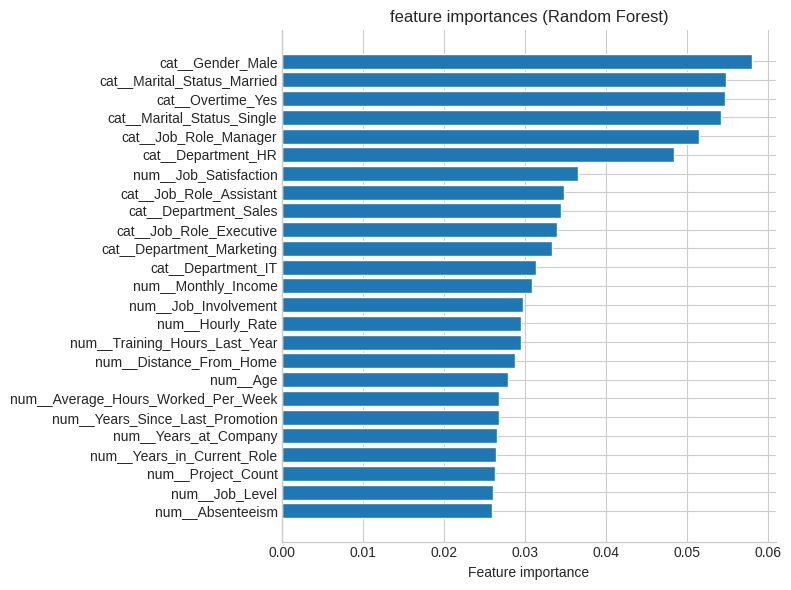

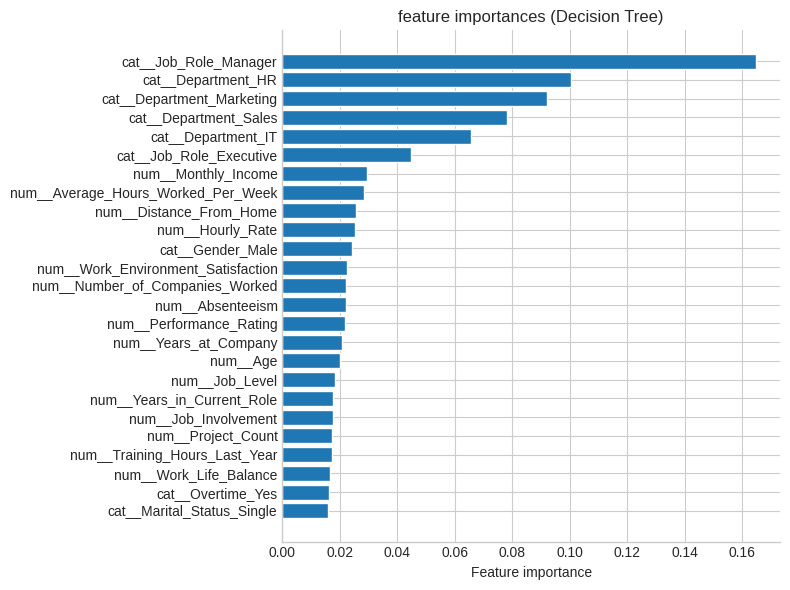

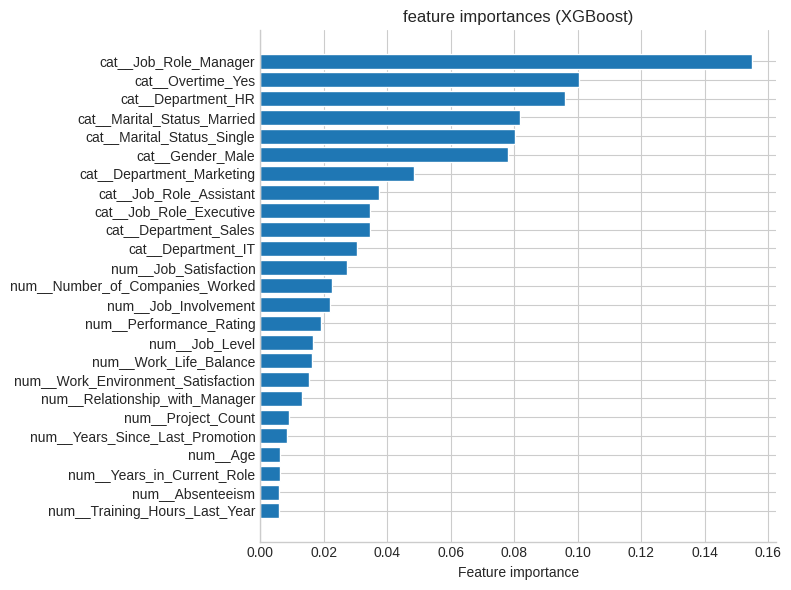

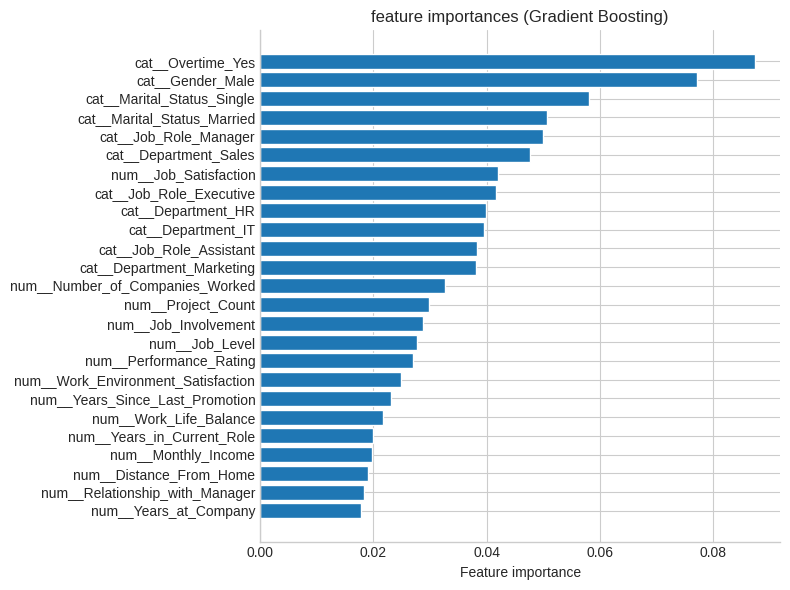

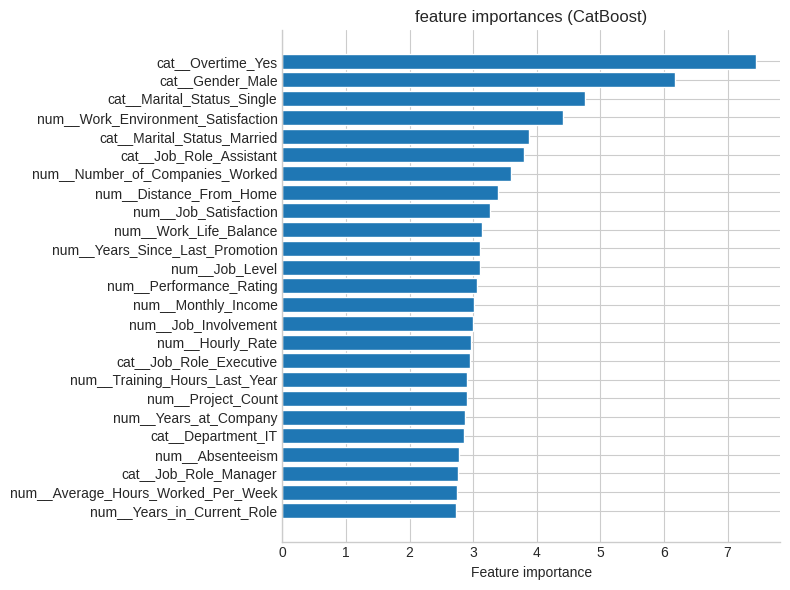

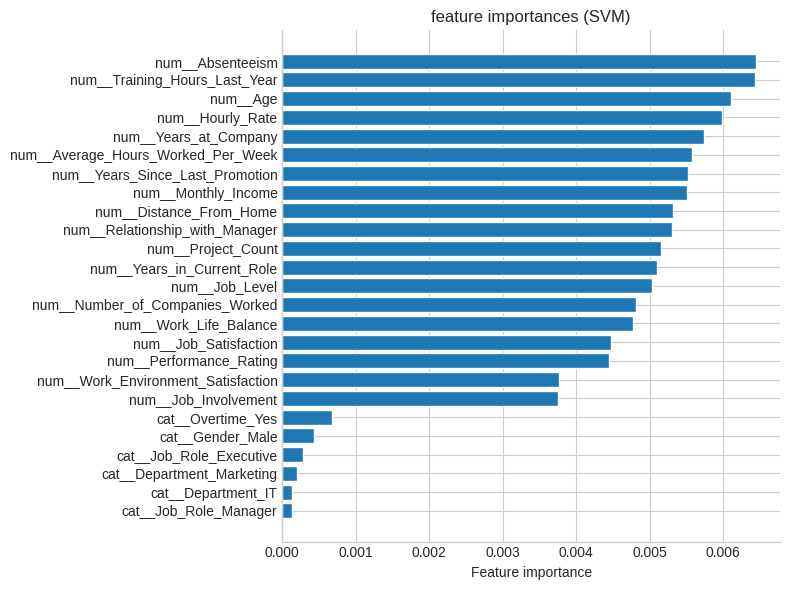

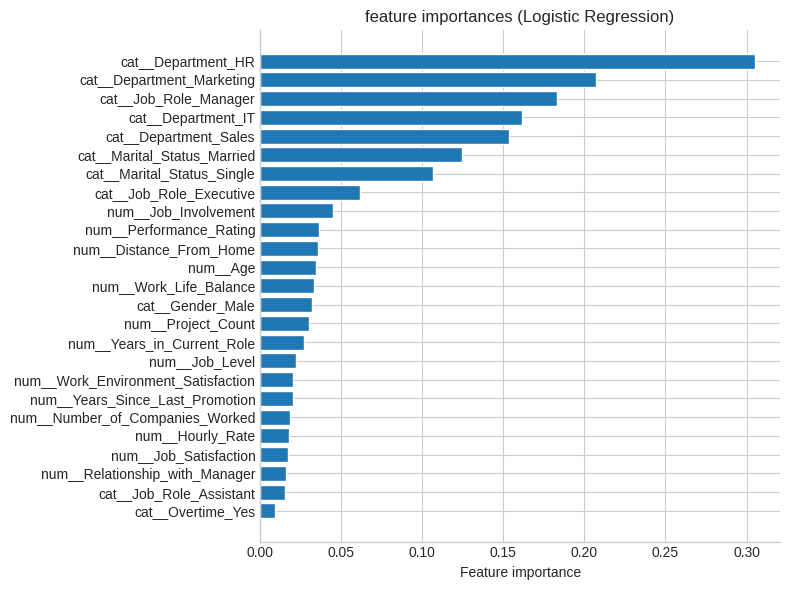

In [ ]:
# Plotting influential features / key predictors for each classifier

chosen_model = ["Random Forest", "Decision Tree", "XGBoost",
                "Gradient Boosting", "CatBoost", "SVM", "Logistic Regression"]

for model in chosen_model:

    plot_s = importance_dict[model].head(25).sort_values()

    plt.figure(figsize=(8, 6))
    plt.barh(plot_s.index, plot_s.values)
    plt.xlabel("Feature importance")
    plt.title(f"feature importances ({model})")
    plt.gca().spines[['top','right']].set_visible(False)
    plt.tight_layout()
    plt.show()


In [ ]:
#   Saving the trained models

print("\n--- Saving All Trained Models using Pickle ---")

from google.colab import files

if not isinstance(models, dict) or not models:
    print("Error: 'models' dictionary is not defined or is empty. Cannot save models.")
else:
    for model_name, model_pipeline in models.items():
        filename = f"{model_name.replace(' ', '_').lower()}_model.pkl"
        try:
            with open(filename, 'wb') as file:
                pickle.dump(model_pipeline, file)
                files.download(filename)        # to download model file
            print(f"Model '{model_name}' saved successfully as: {filename}")
        except Exception as e:
            print(f"Error saving model '{model_name}': {e}")

    print("\n--- Model Saving Process Complete ---")



--- Saving All Trained Models using Pickle ---


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model 'Random Forest' saved successfully as: random_forest_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (12 outputs left out)

Model 'Gradient Boosting' saved successfully as: gradient_boosting_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model 'CatBoost' saved successfully as: catboost_model.pkl

--- Model Saving Process Complete ---
